In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [ ]:
df = pd.read_csv('../Data/Diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [11]:
from scipy.stats import zscore
from sklearn.linear_model import LinearRegression

z_scores = df.apply(zscore)
mask = (z_scores.abs() <= 3).all(axis=1)
df_clean = df[mask]

df_clean = df_clean.drop('Outcome', axis=1)

X = df_clean.drop('DiabetesPedigreeFunction', axis=1)
y = df_clean['DiabetesPedigreeFunction']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=0)


model = LinearRegression()
model.fit(X_train, y_train)
model.score(X_test, y_test)

0.07103618323138383

<Axes: >

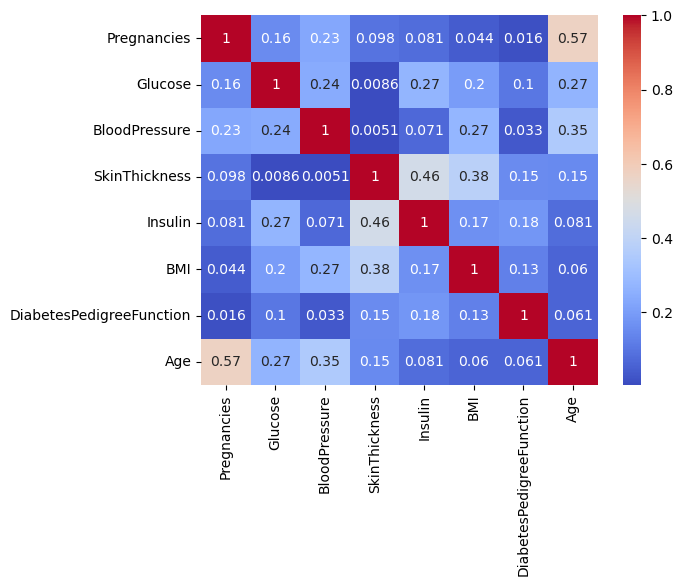

In [12]:
sns.heatmap(df_clean.corr().abs(), annot=True, cmap='coolwarm')